# Forecasting Hands and Objects, joined to narrations

This notebook loads the Ego4D Forecasting Hands and Objects train and validation tables and joins each verb to one narration sentence. It then loads the AgiBot World Beta command sentences and maps them onto the shared verbs. Every count, filter, and figure comes from `src/eg04d_join.py`. The cells below only call that module.

Ego4D is read from `/Users/riaaleksanyan/data/ego4d`. AgiBot is read from `/Users/riaaleksanyan/data/agibot/task_info`.

## Setup

Import the join module and point it at the local annotation directory.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src" / "eg04d_join.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import eg04d_join as join

EGO4D_DIR = Path("/Users/riaaleksanyan/data/ego4d")
if not EGO4D_DIR.exists():
    EGO4D_DIR = ROOT / "data" / "ego4d"
AGIBOT_DIR = Path("/Users/riaaleksanyan/data/agibot/task_info")
DATA_DIR = EGO4D_DIR
DATA_DIR, AGIBOT_DIR

(PosixPath('/Users/riaaleksanyan/Documents/Princeton/project-424/data/ego4d'), PosixPath('/Users/riaaleksanyan/data/agibot/task_info'))

## Load the joined table

Repeated forecast rows collapse to one action. A narration is kept only when its timestamp falls inside the action window. The revised narration pass is used when a video has one. The camera-wearer tag is removed, and the verb, including the words inside a label such as `take (pick, grab, get)`, is removed from the sentence.

In [2]:
paths = join.resolve_annotation_paths(DATA_DIR)
notes, counts = join.build_joined_table(DATA_DIR)
narrations = join.load_narrations(paths.narrations)
scoring = join.scoring_rows(notes)
notes.shape

(67655, 15)

## Descriptive statistics

Joined rows still include ambiguous matches. Scoring rows are the ones a later model is allowed to see.

In [3]:
join.descriptive_statistics(notes)

joined_rows              67655.000000
scoring_rows             41449.000000
videos                    1108.000000
participants               213.000000
verbs                      114.000000
train_rows               44817.000000
val_rows                 22838.000000
median_leftover_words        4.000000
mean_leftover_words          4.720017

## Verb frequency

The distribution below is the scoring set: one row per collapsed action that joined a single narration.

In [4]:
join.verb_frequency(scoring)

verb
put_(place,_leave,_drop)                           8778
take_(pick,_grab,_get)                             7069
hold_(support,_grip,_grasp)                        2040
move_(transfer,_pass,_exchange)                    2035
remove                                             1383
adjust_(regulate,_increase/reduce,_change)         1355
cut_(trim,_slice,_chop)                            1260
open                                               1105
clean_(sweep,_scrub,_mop,_dust)                    1040
touch                                               883
turn_(spin,_rotate,_flip,_turn_over)                791
pour                                                715
paint                                               692
pull                                                650
close                                               638
throw_(toss,_dump,_dispose)                         605
lift                                                600
wash                                       

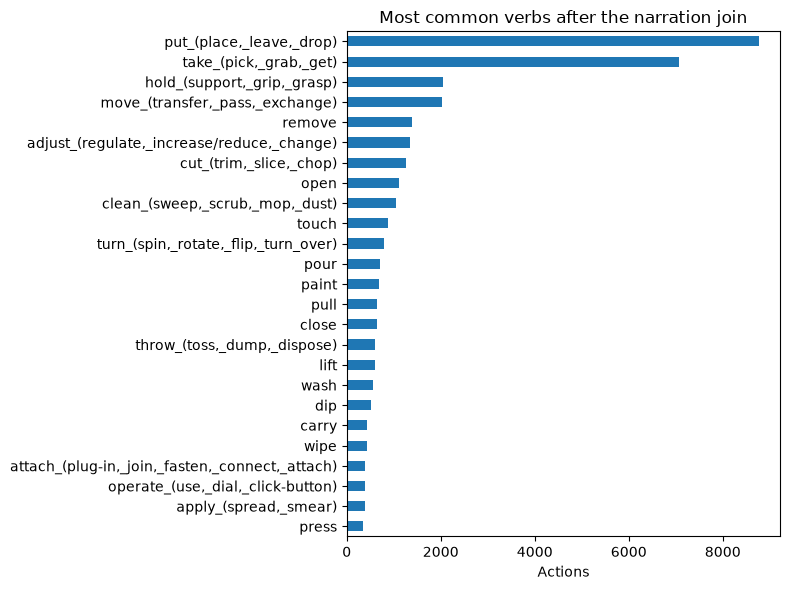

In [5]:
join.plot_verb_frequency(scoring)

## Narrations per video

These counts come from the narration file, before the join. Each video contributes the revised pass when that pass exists, and the original pass otherwise.

In [6]:
per_video = join.narrations_per_video(narrations)
join.narration_video_summary(per_video)

videos                    8886.0
narration_sentences    2515187.0
median_per_video           171.0
max_per_video             5327.0

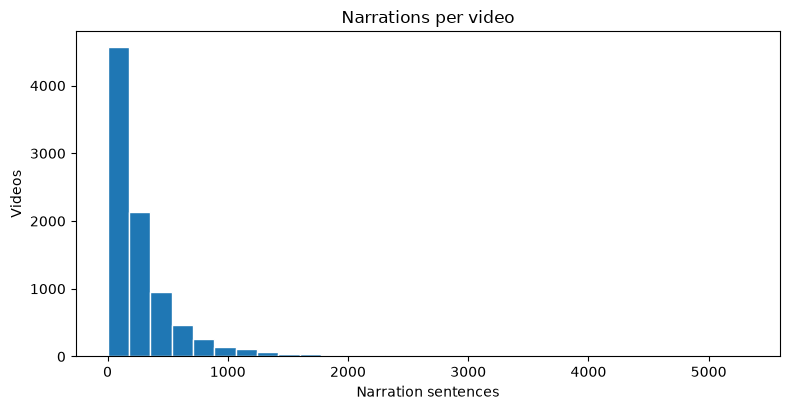

In [7]:
join.plot_narrations_per_video(per_video)

## Preprocessing

The join already removed a leading `C` or `#C` tag and deleted the labeled verb from each sentence. `verb_remains` is true when a form of that verb is still in the leftover, which means the strip missed it. Ambiguous rows, where two sentences inside the window are about equally close, stay in the table and are dropped by `scoring_rows`.

In [8]:
join.preprocessing_summary(notes)

rows_with_narration       67655.0
ambiguous_rows            26206.0
rows_kept_for_scoring     41449.0
verb_still_in_leftover        0.0
empty_leftovers              19.0
median_leftover_words         5.0

In [9]:
join.preprocessing_examples(notes)

,split,verb,narration,leftover,verb_remains,ambiguous
0,train,"put_(place,_leave,_drop)",pours more water in the plastic tin.,pours more water in the plastic tin,False,False
1,train,"hold_(support,_grip,_grasp)",pours more water in the plastic tin.,pours more water in the plastic tin,False,False
2,train,mix,pours more water in the plastic tin.,pours more water in the plastic tin,False,False
3,train,"take_(pick,_grab,_get)",pours more water in the plastic tin.,pours more water in the plastic tin,False,False
4,train,carry,puts the cup of water on the sink.,puts the cup of water on the sink,False,True
5,train,"put_(place,_leave,_drop)",puts the cup of water on the sink.,the cup of water on the sink,False,False
6,train,"take_(pick,_grab,_get)",puts the cup of water on the sink.,puts the cup of water on the sink,False,False
7,train,"put_(place,_leave,_drop)",puts the cup of water on the sink.,the cup of water on the sink,False,False


## Preliminary results

Collapsed actions are the denominator. Rows surviving the join matched one narration and were not ambiguous. Ambiguous rows are excluded from scoring. The last count is validation rows whose participant also appears on a training action. The split is by video, so the same person can sit on both sides.

In [10]:
join.counts_table(counts)

,count
collapsed actions,97001
rows surviving the join,41449
ambiguous rows dropped,26206
validation rows whose participant is also in training,12094


## AgiBot commands

Each `action_text` is one robot command. The shared verbs are the Ego4D taxonomy heads that are also an AgiBot skill name. The skill is the label when it is on that list. Otherwise a command is mapped only when exactly one shared verb appears in the sentence. The verb word is removed before labeling.

In [11]:
shared = join.shared_verbs(DATA_DIR, AGIBOT_DIR)
commands = join.load_agibot_commands(AGIBOT_DIR, shared)
join.agibot_counts(commands, shared)

task_files                    217
command_rows              1001585
shared_verb_list               37
commands_mapped            636365
commands_unmapped          365220
verbs_with_a_command           37
verb_still_in_leftover          0

In [12]:
join.agibot_examples(commands)

,task_id,skill,action_text,leftover,shared_verb,verb_remains
0,327,Pick,Retrieve cucumber from the shelf.,retrieve cucumber from the shelf,,False
1,327,Place,Place the held cucumber into the plastic bag in the shopping cart.,the cucumber into the plastic bag in the shopping cart,hold,False
2,327,Pick,Retrieve tomato from the shelf.,retrieve tomato from the shelf,,False
3,327,Place,Place the held tomato into the plastic bag in the shopping cart.,the tomato into the plastic bag in the shopping cart,hold,False
4,327,Pick,Retrieve corn from the shelf.,retrieve corn from the shelf,,False
5,327,Place,Place the held corn into the shopping cart's plastic bag.,the corn into the shopping cart's plastic bag,hold,False
6,327,Pick,Retrieve pear from the shelf.,retrieve pear from the shelf,,False
7,327,Place,Place the held pear into the plastic bag in the shopping cart.,the pear into the plastic bag in the shopping cart,hold,False


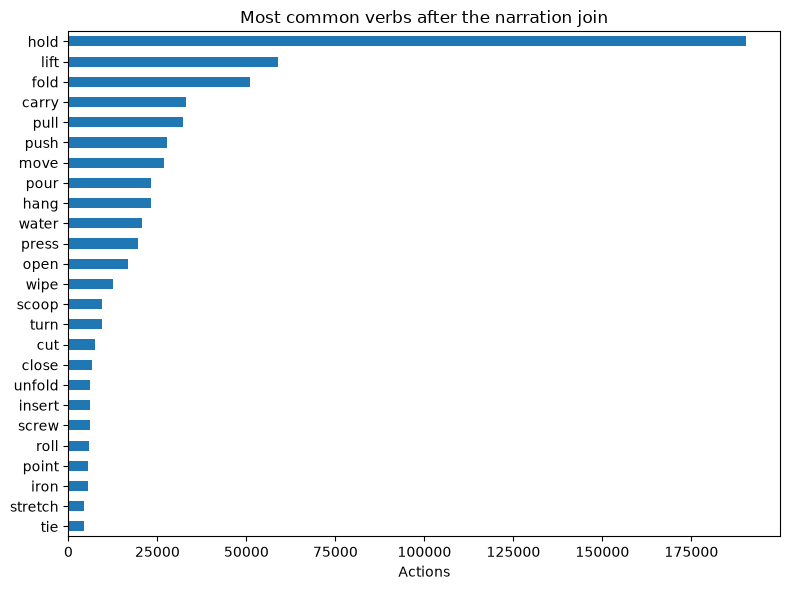

In [13]:
join.plot_verb_frequency(join.agibot_plot_frame(commands))